In [1]:
import pandas as pd

# Load dataset
diabetes_data = pd.read_csv("diabetes.csv")

# Quick preview
print(diabetes_data.info())
display(diabetes_data.head())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Define predictor features and target
features = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'
]

X = diabetes_data[features]
y = diabetes_data['Outcome']

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X shape: (768, 8)
y shape: (768,)


|--- Glucose <= 127.50
|   |--- Age <= 28.50
|   |   |--- BMI <= 45.40
|   |   |   |--- class: 0
|   |   |--- BMI >  45.40
|   |   |   |--- class: 1
|   |--- Age >  28.50
|   |   |--- BMI <= 26.35
|   |   |   |--- class: 0
|   |   |--- BMI >  26.35
|   |   |   |--- class: 0
|--- Glucose >  127.50
|   |--- BMI <= 29.95
|   |   |--- Glucose <= 145.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  145.50
|   |   |   |--- class: 1
|   |--- BMI >  29.95
|   |   |--- Glucose <= 157.50
|   |   |   |--- class: 1
|   |   |--- Glucose >  157.50
|   |   |   |--- class: 1



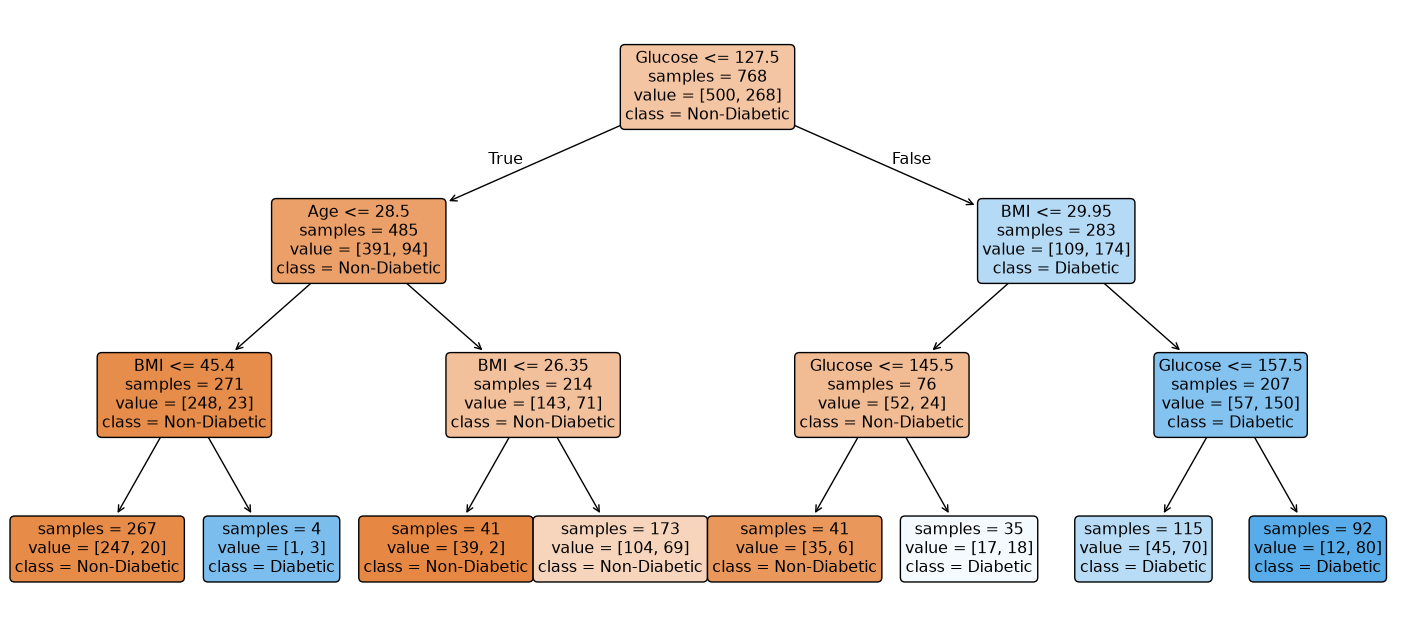


--- Feature Importance ---
Pregnancies: 0.0000
Glucose: 0.6270
BloodPressure: 0.0000
SkinThickness: 0.0000
Insulin: 0.0000
BMI: 0.2519
DiabetesPedigreeFunction: 0.0000
Age: 0.1212


In [3]:
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import plot_tree, export_text

# Initialize and train Decision Tree
DTree = tree.DecisionTreeClassifier(max_depth=3, random_state=42)
DTree.fit(X, y)

# Text representation
print(export_text(DTree, feature_names=features))

# Plot the tree
plt.figure(figsize=(18, 8))
plot_tree(
    DTree,
    filled=True,
    rounded=True,
    impurity=False,
    feature_names=features,
    class_names=['Non-Diabetic', 'Diabetic']
)
plt.show()

# Check Feature Importance
print("\n--- Feature Importance ---")
for name, importance in zip(features, DTree.feature_importances_):
    print(f"{name}: {importance:.4f}")

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20, stratify=y
)

# Fit on training data and predict on test data
DTree.fit(X_train, y_train)
y_pred = DTree.predict(X_test)

# Confusion Matrix & Metrics
cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("Confusion Matrix:\n", cm)
print(f"\nAccuracy: {acc:.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

Confusion Matrix:
 [[94  6]
 [26 28]]

Accuracy: 0.7922

Classification Report:
               precision    recall  f1-score   support

Non-Diabetic       0.78      0.94      0.85       100
    Diabetic       0.82      0.52      0.64        54

    accuracy                           0.79       154
   macro avg       0.80      0.73      0.75       154
weighted avg       0.80      0.79      0.78       154

